# 05 · 服务保护与分布式事务


## 本章来源与学习路线

本篇依据百度网盘 `我的资源/day05-服务保护和分布式事务/PPT/服务保护和分布式事务.pptx`。原文件共 **56 页**，第 **6、12 页隐藏**，网盘预览显示 54 页。下文页码按原 PPT 顺序，隐藏页的失败处理说明也纳入笔记。整理日期：2026-10-09。

课件预览：[服务保护和分布式事务](https://pan.baidu.com/pfile/docview?path=%2F%E6%88%91%E7%9A%84%E8%B5%84%E6%BA%90%2Fday05-%E6%9C%8D%E5%8A%A1%E4%BF%9D%E6%8A%A4%E5%92%8C%E5%88%86%E5%B8%83%E5%BC%8F%E4%BA%8B%E5%8A%A1%2FPPT%2F%E6%9C%8D%E5%8A%A1%E4%BF%9D%E6%8A%A4%E5%92%8C%E5%88%86%E5%B8%83%E5%BC%8F%E4%BA%8B%E5%8A%A1.pptx&fsid=11372719441598&size=1394416&view_from=personal_file&md5=548bae514te96229312e7fcf67e41b31&share=0&client=web&scene=main)。

| 阶段 | 原 PPT 页码 | 核心问题 |
| --- | --- | --- |
| 雪崩与保护方案 | 5—15 | 下游故障怎样拖垮上游，如何阻止扩散 |
| Sentinel | 16—34 | 如何对资源限流、隔离、降级和熔断 |
| 分布式事务与 Seata | 35—47 | 多服务写数据库怎样协调一致性 |
| XA 与 AT | 48—56 | 两阶段中何时提交，怎样回滚，如何取舍 |

补充核对了同目录资料中的 `seata-at.sql`、`seata-tc.sql` 网页代码预览，以及 `资料/seata/application.yml` 原文件。资料清单包含 Sentinel Dashboard 1.8.6 和 Seata 1.5.2 文件，课件控制台截图也是 Sentinel 1.8.6；这些是课程时期的资料标识，不表示当前机器已经运行相应版本。

**版本与示例**：延续 Java 11、Spring Boot 2.x、Spring Cloud 2021.0.x 时代的配置；各 starter 的版本由兼容的父 POM 管理。“课件方案”来自材料，“整理示例”补足阅读需要，“补充/改进”解释边界。已读取课件和关键截图，未启动服务、执行建表 SQL、运行 JMeter 或验证课程源码。


## 1. 服务雪崩的形成

购物车查询依赖商品服务。如果商品响应变慢，购物车线程持续等待；并发请求继续进入，线程、连接或队列可能被占满，其他业务也无法处理。（课件第 7—8 页）

**服务雪崩**：一个服务的故障或阻塞，经调用依赖和资源争用扩散，造成多个服务级联不可用。并不要求每一次下游故障都必然拖垮整个集群。

```text
商品服务慢 / 故障
    ↓
购物车远程调用长时间等待
    ↓
购物车的工作线程、连接与队列被占用
    ↓
购物车其他接口也变慢
    ↓
依赖购物车的上游继续积压
```

| 原因 | 为什么会放大 |
| --- | --- |
| 缺少合理超时 | 单次调用等待过久 |
| 无并发隔离 | 一个依赖占用全部公共资源 |
| 无限或过度重试 | 故障时给下游施加更多流量 |
| 请求持续超过容量 | 队列增长，延迟和资源占用增加 |
| 失败没有明确处理 | 上游继续等待或误判业务状态 |

处理方向包括提高提供者稳定性、把流量限制在容量范围内，并在调用方隔离故障和明确失败结果。网络畅通和代码健壮只是基础，不能代替调用链保护。


## 2. 限流、隔离、降级与熔断

不同保护手段解决不同环节的问题。（课件第 10—14 页）

| 手段 | 控制什么 | 购物车例子 |
| --- | --- | --- |
| 请求限流 | 单位时间请求量或其他流量指标 | 查询购物车入口限制 QPS |
| 并发隔离 / 舱壁 | 某项业务允许同时占用的资源 | 查询商品最多同时执行 5 次 |
| 失败处理 / fallback | 被拒绝或调用失败后的业务结果 | 返回明确的暂时不可用提示 |
| 熔断 | 一段时间内暂停调用故障依赖 | 商品接口持续慢时快速拒绝新调用 |

**舱壁模式**借鉴船舱隔板：一个区域进水，不应淹没整艘船。应用中则为不同业务或依赖设置资源边界。

限流与隔离主要限制资源占用；熔断根据历史调用状况判断是否继续调用；fallback 决定失败后如何表达业务结果。熔断本身不会自动提供合理的降级数据。

超时是这些方案的基础补充：调用方不能因为已有熔断器，就允许每个请求无限等待。


## 3. QPS 与并发数的区别

课件同时使用 QPS 和“并发线程数”，需要先区分它们。（课件第 10、25 页）

| 指标 | 含义 | 单位 |
| --- | --- | --- |
| QPS | 每秒完成或进入的请求数量，需明确统计口径 | 次 / 秒 |
| 并发数 | 某一时刻仍在处理的请求或调用数量 | 个 |
| 响应时间 | 一个请求从开始到完成的耗时 | 秒或毫秒 |

稳定负载下，可用近似关系理解：

```text
平均在途请求数 ≈ 吞吐量 × 平均响应时间

10 次/秒 × 0.5 秒 ≈ 5 个在途请求
10 次/秒 × 2 秒   ≈ 20 个在途请求
```

同样的 QPS，下游变慢会增加并发占用。只限制 QPS，未必能挡住慢调用耗尽资源。

课件说“5 个线程，每线程 QPS 为 2，总 QPS 为 10”，是在耗时约 0.5 秒、资源持续利用等理想条件下的估算，不是并发阈值自动保证的吞吐量。生产阈值应结合负载测试、延迟和资源余量确定。


## 4. Sentinel 核心库与控制台

Sentinel 是阿里巴巴开源的流量治理组件，提供资源统计、流控、熔断和相关整合。（课件第 15、18 页）

| 部分 | 作用 | 部署位置 |
| --- | --- | --- |
| Sentinel 核心库 / 客户端 | 在请求执行时统计并判断规则 | 嵌入每个受保护应用 |
| Sentinel Dashboard | 查看监控、资源和管理规则 | 独立控制台 |

**规则判断发生在应用内**，控制台不是每次业务请求必经的代理。控制台短时不可用时，应用中已经加载的本地规则通常仍可判断，但规则分发和观测会受影响。

课件与 Hystrix 的比较反映历史生态：

| 能力 | Sentinel 的课件方案 | Hystrix 的历史方案 |
| --- | --- | --- |
| 隔离 | 信号量式并发隔离 | 线程池或信号量隔离 |
| 熔断统计 | 慢调用比例、异常比例等 | 异常比率等 |
| 流控 | QPS 与流量整形等 | 支持范围较有限 |
| 控制台 | 可查看资源并配置规则 | 需要组合相关监控组件 |

不能把“Sentinel 配置重启后失效”当成框架不可改变的特性。课件展示的是控制台直接修改内存规则的教学方式；持久化数据源可以解决规则恢复问题。


## 5. Sentinel 接入与资源可见性

**整理补充：客户端依赖**，需与 Spring Cloud Alibaba 版本配套：

```xml
<dependency>
    <groupId>com.alibaba.cloud</groupId>
    <artifactId>spring-cloud-starter-alibaba-sentinel</artifactId>
</dependency>
```

**课件配置**：

```yaml
spring:
  application:
    name: cart-service
  cloud:
    sentinel:
      transport:
        dashboard: "${SENTINEL_DASHBOARD:127.0.0.1:8090}"
      http-method-specify: true
```

独立控制台的启动命令示例，资料提供的是 1.8.6 Jar：

```shell
java -Dserver.port=8090 -jar sentinel-dashboard-1.8.6.jar
```

这里只展示命令，本次没有执行。控制台与客户端需要互相通信：应用能访问 dashboard，dashboard 也需能访问客户端通信端口；容器内的 localhost 指向当前容器。

Sentinel 接入常有延迟初始化行为。应用首次被调用后才可能上报资源与监控；控制台暂时看不到服务时，应先确认请求进入了应用，再查网络和配置。

控制台版本与客户端依赖版本应核对兼容性，不能只按 Jar 文件名选择所有 starter 的版本。


## 6. 资源与簇点链路

规则必须绑定到可监控的资源。课件的**簇点链路**指一次请求在单个应用内经过的 Sentinel 资源链，不是跨全部微服务的完整分布式调用追踪。（课件第 19—20 页）

Spring MVC 整合默认会对 HTTP 接口创建资源。开启 `http-method-specify` 后，同一路径可以按方法区分：

```text
GET:/carts       查询购物车
POST:/carts      添加商品
PUT:/carts       修改数量
DELETE:/carts/{id} 删除条目

GET:/carts
    └── GET:http://item-service/items  # Feign 调用资源的课件示意
```

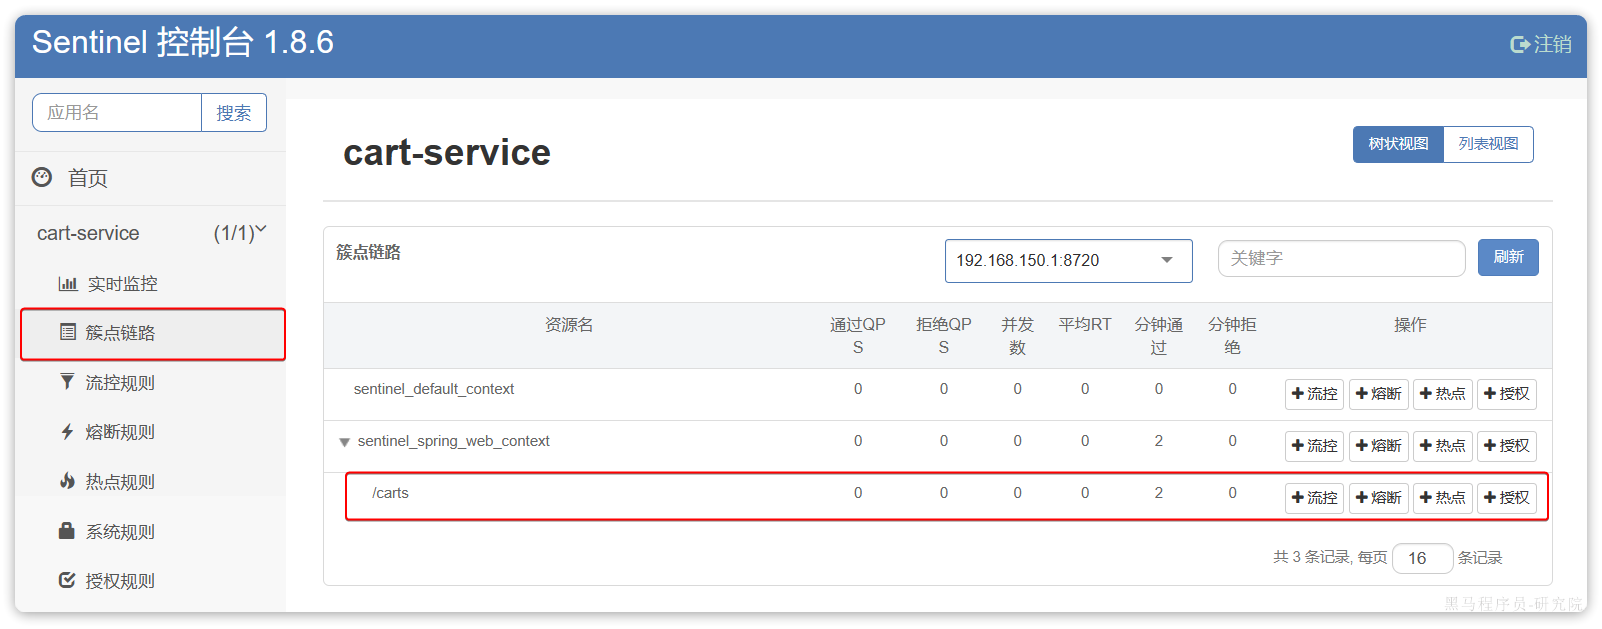

| 资源位置 | 规则影响范围 |
| --- | --- |
| 购物车入口资源 | 进入这项接口的请求 |
| 购物车中的商品 Feign 资源 | 当前应用对商品接口的远程调用 |
| 商品服务入口资源 | 到达商品服务的请求 |

在购物车服务限制 Feign 并发，能够保护购物车的资源；在商品服务入口限流，则保护商品服务本身。它们的位置与目的不同。

资源名称要以实际控制台或指标为准。HTTP 方法前缀、路径模板、Feign 适配版本等都会影响名字；不能把图片里的字符串直接套到不同工程。


## 7. QPS 流控规则

入口流量超过容量时，可以在对应资源上配置 QPS 阈值。（课件第 22 页）

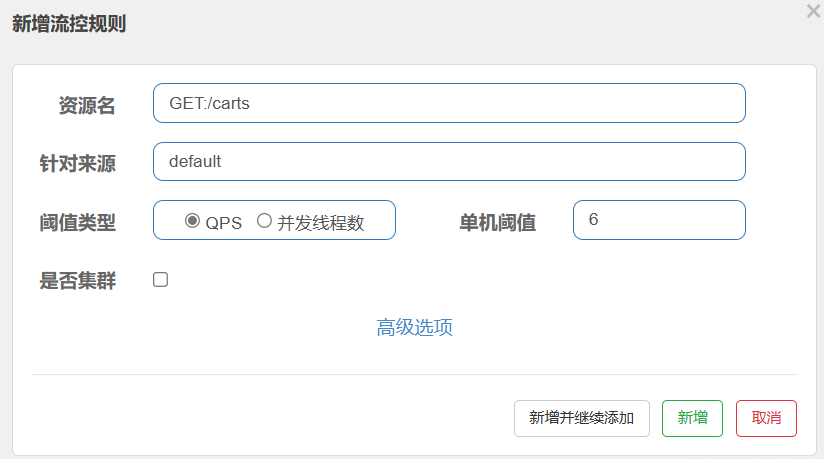

| 截图字段 | 含义 |
| --- | --- |
| 资源名 | GET:/carts |
| 针对来源 default | 默认来源规则，不等于用户 ID 维度 |
| 阈值类型 QPS | 控制单位时间通过量 |
| 单机阈值 6 | 该应用实例上的阈值 |
| 是否集群未勾选 | 不构成整个集群共享的总额度 |

使用多个实例时，单机限流不会自动形成全局统一的 6 QPS。整体通过量还取决于流量分配等因素，不能简单当成集群阈值。

联调可持续发送超过阈值的请求，观察通过、阻塞和延迟指标。滑动窗口统计、突发流量和实际采样会影响瞬时结果，不能期待每一秒都恰好通过 6 次。

被流控拒绝属于保护规则触发，不等于商品业务失败。入口应提供明确的错误状态与响应结构；具体阻塞响应由实际 Web 适配和异常处理配置决定。


## 8. Sentinel 的并发隔离

查询购物车中的商品调用变慢时，要限制这项依赖同时占用的请求线程数量。（课件第 24—25 页）

Sentinel 常用**信号量式隔离**：资源进入时检查当前并发额度，超过阈值就拒绝进入；调用仍在原线程执行，并不会为该资源创建独立线程池。

```text
商品查询并发额度：5
    ├── 5 个调用正在执行 → 已占满
    └── 第 6 个调用进入 → 快速拒绝 / 触发失败处理

原来的 5 个调用仍需靠超时等机制结束
```

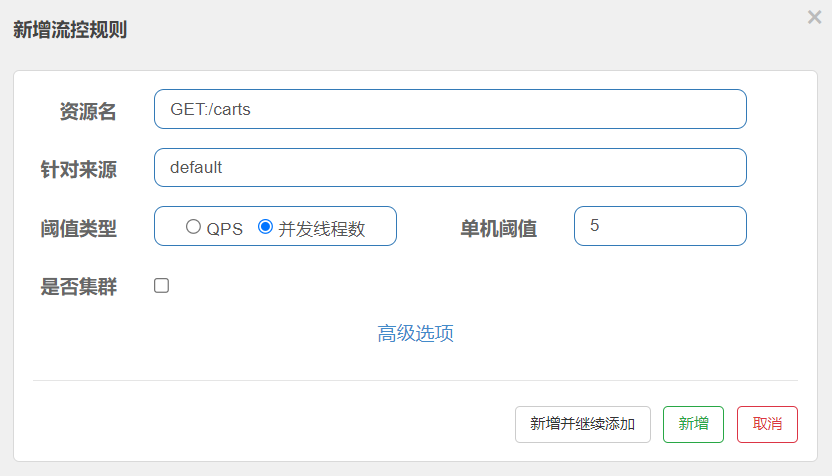

**截图与目标需区分**：此截图的资源名仍是 `GET:/carts`，而页面文字的目标是限制购物车内的商品查询。在自己的工程中，若只想隔离商品依赖，应选实际 **Feign 商品查询资源**；选入口资源会限制整个购物车请求的并发。

| 隔离方式 | 优点 | 代价 / 边界 |
| --- | --- | --- |
| 信号量式并发限制 | 开销低，沿用当前线程 | 已进入的慢调用仍占原线程 |
| 独立线程池隔离 | 依赖之间有更直接的线程资源边界 | 线程切换、队列与上下文传播需要管理 |

并发阈值不是线程池大小，也不是单次调用超时。把阈值设为 5，并不意味着被阻塞的线程会自动取消或在 5 秒后释放。


## 9. Feign 的 FallbackClass 与 FallbackFactory

当远程服务超时、故障，或调用被保护规则拒绝时，调用方需要明确后备行为。（课件第 27—30 页）

**课件 Feign-Sentinel 整合开关**：

```yaml
feign:
  sentinel:
    enabled: true
```

仍需 OpenFeign、Sentinel 及相应自动配置正常工作；仅写开关，不会凭空产生客户端或规则。不要将它与其他版本、其他熔断整合方案的配置混用。

| 方式 | 声明 | 对失败原因的访问 |
| --- | --- | --- |
| 固定 fallback 实现类 | `fallback = XxxFallback.class` | 通常没有按次获取 cause 的入口 |
| fallback 工厂 | `fallbackFactory = XxxFallbackFactory.class` | `create(Throwable cause)` 接收本次失败原因 |

课件“FallbackClass 无法处理异常”更准确地说，是它不像工厂那样直接得到本次调用的 Throwable；它仍能定义失败时的返回行为。

fallback 类或工厂必须注册为 Bean，并位于客户端可用的配置范围。某个调用是否触发 fallback，还要按实际适配版本和异常种类验证。


## 10. FallbackFactory 的整理示例

课件用 UserClient 演示工厂，这里延续商城的 ItemClient，展示如何保留原始失败原因。（课件第 28—30 页）

**客户端契约**：

```java
@FeignClient(
    name = "item-service",
    fallbackFactory = ItemClientFallbackFactory.class
)
public interface ItemClient {
    @GetMapping("/items")
    List<ItemDTO> queryItemByIds(@RequestParam("ids") Collection<Long> ids);
}
```

**工厂注册为 Bean**：

```java
@Component
public class ItemClientFallbackFactory
        implements FallbackFactory<ItemClient> {
    private static final Logger log =
        LoggerFactory.getLogger(ItemClientFallbackFactory.class);

    @Override
    public ItemClient create(Throwable cause) {
        return ids -> {
            log.warn("商品查询调用失败，ids={}", ids, cause);
            throw new ItemQueryUnavailableException("商品查询暂不可用", cause);
        };
    }
}
```

```java
public class ItemQueryUnavailableException extends RuntimeException {
    public ItemQueryUnavailableException(String message, Throwable cause) {
        super(message, cause);
    }
}
```

关键 import 是课件时代整合中的 `org.springframework.cloud.openfeign.FallbackFactory`；日志使用 SLF4J 的 Logger。不要套用旧 Hystrix 包中的同名工厂类型。

工厂需有所有接口方法的实现；单方法接口可以如上用 lambda。消费者的 Feign 扫描与 fallback Bean 扫描都要核对，例如共享 hm-api 包在启动类范围外时，应显式指定 Client 并导入必要配置。

示例选择抛出明确业务异常，交给上层异常处理返回友好失败。它不是成功降级数据，也没有吞掉 cause。真实工程日志还应限制 ID 数量、避免高频故障造成日志风暴。


## 11. 降级结果必须有业务含义

课件的 UserClient fallback 返回 null，只是演示。照搬到购物车查询或下单业务，可能产生数据误判。（课件第 12 隐藏页、14、29 页）

| 场景 | 可以考虑的后备行为 | 不应伪装的结果 |
| --- | --- | --- |
| 商品展示 | 明确提示实时价格不可用，或标注使用缓存 | 把旧价格当成最新价格 |
| 非关键推荐 | 返回约定的空推荐集合 | 把业务失败与正常无数据混为一谈 |
| 库存扣减 | 明确失败、停止下单或进入恢复流程 | 返回“扣减成功” |
| 账户扣款 | 保留真实失败与未知结果 | 返回“支付成功” |

> 下游超时不表示它一定没有执行。对于写操作，未知结果需要幂等和状态查询；不能只重试到返回成功为止。

fallback 可以返回约定数据，也可以抛出明确异常。选择取决于业务是否允许继续，以及调用方是否能够区分真实结果、降级结果与失败。

服务保护关注可用性，不能为了“接口不报错”破坏业务正确性。这个边界在后面的分布式事务中尤其重要。


## 12. 熔断器的状态转换

并发隔离只能限制资源占用，不能阻止消费者持续尝试一个长期故障的依赖。熔断器统计调用质量，在达到规则阈值后暂停调用。（课件第 32—33 页）

```text
CLOSED：正常允许调用，并统计结果
    │ 达到异常 / 慢调用阈值
    ▼
OPEN：快速拒绝新调用
    │ 熔断时间结束
    ▼
HALF-OPEN：允许探测请求
    ├── 探测结果满足恢复条件 → CLOSED
    └── 探测失败 / 仍然慢 → OPEN
```

| 状态 | 行为 |
| --- | --- |
| Closed | 断路器关闭，调用链接通 |
| Open | 断路器打开，新调用快速失败 |
| Half-Open | 少量探测，判断是否恢复 |

Sentinel 1.8.x 常见半开探测逻辑为放行一次请求，是否成功还要结合所用策略判断；慢调用策略不能只按“HTTP 返回 200”判断恢复。

熔断作用于配置的资源和对应客户端实例，通常不是把整个商品服务在所有调用方上统一关闭。已进入执行的请求也不会因熔断状态变化而自动中断。


## 13. 熔断策略与截图参数

课件控制台可选择慢调用比例、异常比例、异常数策略。（课件第 34 页）

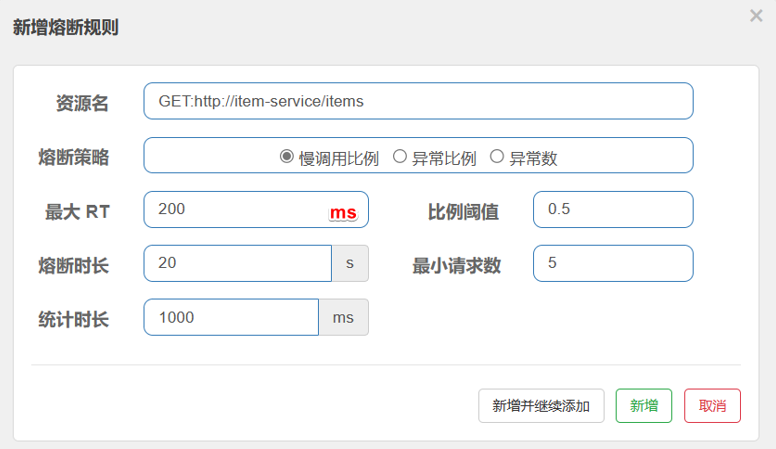

| 截图参数 | 值 | 含义 |
| --- | --- | --- |
| 资源 | GET:http://item-service/items | 被统计和保护的调用资源 |
| 最大 RT | 200 ms | 超过此响应时间的调用记为慢调用 |
| 比例阈值 | 0.5 | 慢调用比例的判断阈值 |
| 最小请求数 | 5 | 样本不足时避免贸然按比例熔断 |
| 统计时长 | 1000 ms | 统计窗口 |
| 熔断时长 | 20 s | 打开状态持续后再进入探测 |

在该示意中，需要统计窗口内样本达到最小数量，再根据慢调用比例判断是否触发。边界是大于还是大于等于等细节，按实际 Sentinel 策略实现核对。

| 策略 | 关注点 | 适合判断的情况 |
| --- | --- | --- |
| 慢调用比例 | 延迟超过 RT 阈值的占比 | 返回成功但持续过慢 |
| 异常比例 | 失败调用占比 | 故障率明显升高 |
| 异常数 | 窗口内异常绝对数量 | 失败次数达到业务容忍上限 |

RT 阈值 **不是读取超时**。200 ms 只用于识别慢调用；一个请求即便已超过 200 ms，也不会因此被自动取消。HTTP 超时仍需单独配置。

熔断样本、统计窗口与时长应结合正常流量、延迟分布和恢复速度设置，不能把课件的 200 ms / 20 s 当成所有接口的默认值。


## 14. 规则持久化与服务保护验证

教学中在控制台添加规则很方便，但直接修改客户端内存规则时，重启应用可能丢失；重启控制台也可能丢失它掌握的状态。（课件第 15 页；持久化为补充）

可以接入 Nacos 等规则数据源。注意：普通配置文件的刷新，与 Sentinel 规则数据源的读取和规则类型转换，是不同整合机制；不能只把规则 JSON 放到 Nacos 就认为控制台修改会自动持久化。

| 要验证的行为 | 检查方法 |
| --- | --- |
| QPS 限流 | 增加入口频率，观察通过与阻塞指标 |
| 并发隔离 | 增加下游耗时，观察在途调用数与拒绝 |
| fallback | 分别测试保护阻塞、网络错误与响应超时 |
| 熔断打开 | 让慢调用 / 异常样本满足规则，观察新调用是否快速失败 |
| 半开恢复 | 等待窗口结束，恢复下游，再检查探测与恢复 |
| 持久化 | 重启应用后确认规则重新加载，而非仅看控制台页面 |

资料提供 `雪崩测试.jmx` 与 JMeter 5.4.1 文件，可用于课程压测准备；本篇没有运行或假定脚本里的地址适合当前环境。

应观察被保护业务和无关业务：商品查询受阻时，其他接口是否仍能响应，才有助于判断隔离是否达到目的。


## 15. 本地事务为什么不够

下单需要创建订单、清理购物车并扣减库存。它们拆到不同服务、不同数据库后，各自的数据库事务只能保护自己的操作。（课件第 36—37 页）

```text
订单服务：订单写入成功       → 订单数据库提交
购物车服务：购物车清理成功   → 购物车数据库提交
商品服务：库存不足，扣减失败 → 商品数据库回滚

可能出现：订单存在、购物车已清空，但库存未扣减
```

**本地事务**通常绑定某个数据库资源与连接，只能让本地 SQL 一起提交或回滚。远程 HTTP 调用不会自动加入调用方的数据库事务。

| 做法 | 可以保证 | 无法自动保证 |
| --- | --- | --- |
| 订单方法 `@Transactional` | 订单服务本地事务 | 购物车、商品数据库一起回滚 |
| 每个服务都 `@Transactional` | 各自本地操作原子性 | 分支之间统一成功或失败 |
| 全局事务协调 | 在适用条件下协调各分支结果 | 任意外部副作用都能回滚 |

客户端不知道另一个数据库已经提交，也就不能靠本地 rollback 撤销它。需要跨资源协调机制，或明确的业务补偿与最终一致性方案。


## 16. 全局事务、分支事务与业务范围

课件把多服务合作完成的业务定义为全局事务，每个服务的事务作为分支事务。（课件第 37、40 页）

| 术语 | 下单对应 |
| --- | --- |
| 全局事务 | 创建订单、清理购物车、扣减库存的整体一致性范围 |
| 分支事务 | 每个参与资源上的本地事务 |
| 事务协调者 | 记录分支状态并协调提交或回滚 |

首先明确哪些操作必须一起成功。课件把清购物车纳入下单事务；真实系统也可能把它作为下单后异步操作，只要求订单与库存遵守更强约束。事务边界由业务决定。

数据库回滚不会自动撤回已发送的短信、第三方支付请求或外部消息。若这些操作参与流程，需要幂等、可靠消息、补偿或其他匹配的方案。

> 分布式事务不是“给所有调用加一个注解”。资源类型、传播机制、隔离要求、失败恢复与业务范围必须匹配。


## 17. Seata 的 TC、TM 与 RM

Seata 是课件采用的分布式事务解决方案，提供 XA、AT 等模式。（课件第 39—41 页）

| 角色 | 职责 | 常见位置 |
| --- | --- | --- |
| TC：Transaction Coordinator | 维护全局 / 分支状态，协调提交与回滚 | 独立 Seata Server |
| TM：Transaction Manager | 开始、结束全局事务，定义范围 | 全局事务入口所在应用 |
| RM：Resource Manager | 管理参与资源、注册分支并执行提交 / 回滚 | 参与事务的各应用 |

```text
订单应用的 TM ──申请全局事务──► TC
                     ◄── XID ──┘

订单 RM ───注册 / 报告分支───► TC
购物车 RM ─注册 / 报告分支───► TC
商品 RM ───注册 / 报告分支───► TC

TM 请求提交或回滚
    → TC 协调所有相关 RM
    → RM 按所选模式处理数据库资源
```

同一个应用可以同时具有 TM 与 RM 角色：订单服务发起全局事务，也在自己的数据库上执行分支操作。

TC 需要可达、可靠且保留协调状态。它不是 Nacos 的替代品；Nacos 可负责发现 TC 地址，但不能代替 TC 的事务协调。


## 18. XID 与跨服务事务传播

多个分支要知道自己属于同一个全局事务，Seata 使用 **XID** 作为全局事务标识。（课件架构的整理补充）

```text
订单服务开始全局事务，得到 XID
    → Feign 调用传播 XID
    → 商品 / 购物车服务绑定同一 XID
    → 本地资源代理按该 XID 注册分支
    → 请求结束后清理上下文
```

| 检查点 | 失败后果 |
| --- | --- |
| 入口实际开启全局事务 | 否则没有全局协调范围 |
| HTTP / Feign 整合传播 XID | 下游可能只提交自己的本地事务 |
| 下游绑定上下文 | 收到字符串也未必注册成分支 |
| 数据源被对应代理接管 | 普通连接操作不一定进入 Seata |
| 上下文生命周期正确 | 线程复用可能出现事务串用 |

可在开发日志中通过 `io.seata.core.context.RootContext.getXID()` 检查入口和下游是否处于预期全局事务，并结合 TC 分支记录确认。XID 一致只是必要证据，还要确认资源代理和分支执行。

starter 的自动整合应按实际版本验证；不要另外复制一套传播拦截器，导致重复绑定或清理冲突。

XID 与上一篇的用户 ID 是不同上下文。用户身份回答“谁在操作”，XID 回答“属于哪次全局事务”；两者都不能假设会自动跨异步线程或消息边界传播。


## 19. TC 服务部署与两种数据库脚本

课件第 43 页引用讲义《2.2.部署 TC 服务》，没有在 PPT 内展开命令。本篇依据已核对的资料文件说明部署要点，不虚构完整讲义内容。

| 文件 | 用途 | 应用位置 |
| --- | --- | --- |
| `seata-tc.sql` | 创建 seata 数据库与 TC 状态表 | TC 自己的存储数据库 |
| `seata-at.sql` | 创建 undo_log | 参与 AT 的每个业务数据库 |
| `seata/application.yml` | TC 的端口、注册、存储等配置 | Seata Server |
| `seata-1.5.2.tar` | 课程提供的部署镜像资料 | 部署准备，使用前确认实际镜像信息 |

已读取的 `seata-tc.sql` 包含以下表：

| 表 | 主要作用 |
| --- | --- |
| global_table | 全局事务状态 |
| branch_table | 分支事务状态 |
| lock_table | 全局锁相关记录 |
| distributed_lock | TC 后台协调任务的锁 |

**部署顺序**：

1. 准备 TC 的数据库，并导入与服务端版本匹配的 TC 脚本。
2. 配置 TC 的数据库连接、注册中心和实际服务地址。
3. 启动 Seata Server，确认数据库连接与注册成功。
4. 从业务服务环境检查 TC 通信端口可达。
5. 再接入业务客户端，确认能够创建全局事务和注册分支。

资料中的 TC 配置使用数据库存储，Nacos 地址为容器主机名 `nacos`，数据库主机名为 `mysql`。这些名字要求对应网络能够解析，并不是所有机器的通用地址。


## 20. TC 控制台端口与事务通信端口

“浏览器能打开 TC 控制台”不等于业务客户端已能连接事务协调服务。

核对的 `application.yml` 设置 `server.port: 7099`，但把 `seata.server.service-port` 注释了；注释说明该版本未显式配置时，事务服务端口默认为 Web 端口加 1000，即该配置下应考虑 **8099**。

若希望使用常见的 8091 事务端口，应明确设置，并让端口映射、注册信息和客户端网络与之对应。

**基于资料改写的配置片段**，合并到与所用版本匹配的完整服务端配置：

```yaml
server:
  port: 7099
spring:
  application:
    name: seata-server
seata:
  config:
    type: file
  registry:
    type: nacos
    nacos:
      application: seata-server
      server-addr: "${NACOS_SERVER_ADDR:nacos:8848}"
      namespace: ""
      group: DEFAULT_GROUP
      cluster: default
  server:
    service-port: 8091
  store:
    mode: db
    db:
      datasource: druid
      db-type: mysql
      driver-class-name: com.mysql.cj.jdbc.Driver
      url: "jdbc:mysql://${TC_DB_HOST:mysql}:3306/seata?serverTimezone=UTC"
      user: "${TC_DB_USERNAME}"
      password: "${TC_DB_PASSWORD}"
      global-table: global_table
      branch-table: branch_table
      lock-table: lock_table
      distributed-lock-table: distributed_lock
```

该片段明确了 RPC 端口并用环境属性替代示例密码；完整的认证、安全和版本专用配置仍需保留并按实际部署设置。

| 地址 / 端口 | 含义 |
| --- | --- |
| Nacos 8848 及版本所需通信端口 | 找到 TC 服务实例 |
| TC Web 7099 | 本资料中的 Web / 控制台端口 |
| TC service-port 8091 | 本整理示例显式指定的事务通信端口 |
| TC 注册 IP | 必须能从业务应用所在网络访问 |

在 Docker 部署时尤其要检查注册出去的是容器内地址还是可达主机地址。需要按该版本机制配置对外地址，例如核对 SEATA_IP 等设置；不能只映射端口就假设 Nacos 广播的地址正确。


## 21. 微服务接入 Seata 与事务组映射

所有参与分支的服务都要引入客户端，并找到同一事务协调环境。（课件第 45—47 页）

**课件依赖**：

```xml
<dependency>
    <groupId>com.alibaba.cloud</groupId>
    <artifactId>spring-cloud-starter-alibaba-seata</artifactId>
</dependency>
```

**application.yml 整理示例**：

```yaml
seata:
  registry:
    type: nacos
    nacos:
      server-addr: "${NACOS_SERVER_ADDR:127.0.0.1:8848}"
      namespace: ""
      group: DEFAULT_GROUP
      application: seata-server
  tx-service-group: hmall
  service:
    vgroup-mapping:
      hmall: default
```

如 Nacos 开启认证，应配置实际允许访问该环境的凭据。本示例省略真实账号，而不是要求关闭认证。

```text
业务事务组 hmall
    → vgroup-mapping.hmall = default
    → 找到 seata-server 的 default 集群
    → 获取可达 TC 实例
```

| 配置 | 作用 |
| --- | --- |
| tx-service-group | 客户端事务分组名称 |
| vgroup-mapping | 从事务组映射到 TC 集群 |
| registry.nacos.application | TC 在 Nacos 中的服务名 |
| namespace / group | TC 注册发现的环境位置 |

事务组与映射键的拼写必须一致，本篇统一为 `hmall`。事务组不是数据库名，也不是 Spring 应用名。

课件要求把公共 Seata 配置共享到 Nacos，可延续上一篇的 bootstrap / shared-configs 方式加载。例如新增 `shared-seata.yaml`，再在各参与服务的共享配置列表中声明。与 Nacos 客户端的配置刷新能力不同，是否允许 TC 连接配置在运行时切换需另外验证。

Seata Server 的注册配置、业务客户端发现 TC 的配置，以及各自的配置中心设置是不同入口，需逐项对应。引入 Seata starter 后，也应检查实际数据源代理和客户端版本，避免重复代理或混入不兼容 Seata 依赖。


## 22. XA 模式的两阶段过程

XA 规范定义了分布式事务处理中事务管理器与资源管理器的协作接口。Seata XA 使用数据库 XA 能力协调分支。（课件第 49—50 页）

```text
第一阶段：
开始全局事务 → 注册分支
→ 分支执行 SQL → 准备事务并报告
→ 尚不完成业务提交，相关资源继续占用

第二阶段：
全部满足提交条件 → TC 协调各分支提交
任一分支失败     → TC 协调各分支回滚
```

| 阶段 | 分支数据库状态 | 关键影响 |
| --- | --- | --- |
| 一阶段执行 / prepare | 尚未最终提交 | 可能持有锁和事务资源 |
| 二阶段 commit | 持久化分支结果 | 结束并释放相关资源 |
| 二阶段 rollback | 数据库撤销分支 | 结束并释放相关资源 |

XA 的 prepare 是可恢复的“准备提交”，比简单地“SQL 执行完但先不提交”更完整。TC 和数据库需要持久化相应状态并具备故障恢复能力。

课件把 XA 归纳为强一致、满足 ACID，理解重点是其数据库级原子提交协调和适当隔离下的一致性。网络分区或协调者故障可能让分支阻塞；多数据库的可见性也不等于同一物理时刻瞬间切换，需结合实际隔离与恢复机制理解。

| 收益 | 代价 |
| --- | --- |
| 使用数据库机制提交和回滚 | 要求驱动、数据库与资源支持 XA |
| 无需手写反向补偿 SQL | 锁与资源持有可能跨越远程调用 |
| 数据库事务语义较直接 | 长事务、高并发与故障恢复成本较高 |


## 23. XA 模式的配置与全局入口

**课件步骤**：每个参与事务的微服务启用 XA 数据源代理，入口方法添加 GlobalTransactional，然后联调。（课件第 51 页）

```yaml
seata:
  data-source-proxy-mode: XA
```

**全局入口整理示例**，方法名和服务接口应与真实工程对应：

```java
@Service
@RequiredArgsConstructor
public class OrderServiceImpl {
    private final OrderWriter orderWriter;
    private final CartClient cartClient;
    private final ItemClient itemClient;

    @GlobalTransactional(name = "create-order", rollbackFor = Exception.class)
    public Long createOrder(OrderFormDTO form) {
        Long orderId = orderWriter.create(form);
        cartClient.removeByItemIds(form.getItemIds());
        itemClient.deductStock(form.getStockDeductItems());
        return orderId;
    }
}
```

其中 OrderWriter、removeByItemIds、deductStock 与 DTO 方法为整理占位契约；ItemClient 与前半篇只查询商品的示例不是同一份完整接口。实际工程需要相应方法与服务端实现。

各分支的本地业务应按需要放在 `@Transactional(rollbackFor = Exception.class)` 范围内，且由实际代理的数据源执行。全局事务与本地事务负责不同层次，不能认为 GlobalTransactional 替代了每个数据库的事务边界。

关键注解为 `io.seata.spring.annotation.GlobalTransactional`。Spring AOP 需要代理调用：在同一个对象内自调用方法，可能绕过注解；异常被内部 catch 并当成功返回，也可能使全局入口判断为成功。

**失败原则**：库存不足等导致业务不能完成时，失败需要传播到全局协调边界。远程接口返回错误包装而不抛异常时，调用方也要检查包装并明确失败。

XA 测试应同时检查订单、购物车与库存数据库，不能仅看入口返回错误就认为所有分支已回滚。


## 24. AT 模式：本地提交与补偿回滚

XA 持有资源直到第二阶段，容易让远程调用时延放大锁占用。AT 在第一阶段提交本地事务，用 undo_log 保存回滚所需信息，第二阶段再确认提交或执行补偿。（课件第 53—55 页）

```text
第一阶段：
读取修改前数据 → 执行业务 SQL → 读取修改后数据
→ 记录 before / after image 与 undo_log
→ 协调分支注册、全局锁
→ 业务修改与 undo_log 在同一本地事务中提交
→ 释放本地数据库事务锁

第二阶段成功：
确认全局提交 → 清理 undo_log 等事务记录

第二阶段失败：
读取 undo_log → 校验当前数据
→ 执行反向恢复 → 清理日志与事务记录
```

实际注册、锁申请与日志写入的内部时序随实现而定。关键约束是本地修改与回滚日志要原子提交，且全局写锁约束不能丢失。

| 快照 | 扣库存例子 |
| --- | --- |
| before image | stock = 100 |
| after image | stock = 99 |
| 回滚目标 | 在通过一致性检查后恢复到 100 |

AT 第二阶段的提交通常主要做日志与状态清理，不再重新执行一遍业务 SQL。回滚使用记录的数据构造补偿，不是简单地给库存无条件加 1。

课件将其归纳为“最终一致”：第一阶段本地已经提交，其他读取可能看到全局完成前的中间状态；失败后依靠补偿和恢复机制达到约定结果，不能当作完全没有中间可见性。


## 25. undo_log 表与业务数据库

AT 回滚依赖 undo_log，每个实际参与 AT 分支的业务数据库都需要匹配版本的表。（课件第 56 页与资料 seata-at.sql）

**课程脚本的表结构**：

```sql
CREATE TABLE IF NOT EXISTS undo_log
(
    branch_id BIGINT NOT NULL COMMENT 'branch transaction id',
    xid VARCHAR(128) NOT NULL COMMENT 'global transaction id',
    context VARCHAR(128) NOT NULL COMMENT 'undo_log context,such as serialization',
    rollback_info LONGBLOB NOT NULL COMMENT 'rollback info',
    log_status INT(11) NOT NULL COMMENT '0:normal status,1:defense status',
    log_created DATETIME(6) NOT NULL COMMENT 'create datetime',
    log_modified DATETIME(6) NOT NULL COMMENT 'modify datetime',
    UNIQUE KEY ux_undo_log (xid, branch_id)
) ENGINE = InnoDB
  AUTO_INCREMENT = 1
  DEFAULT CHARSET = utf8mb4 COMMENT = 'AT transaction mode undo table';
```

此处去掉标识符反引号以便阅读，字段与类型沿用所核对课程脚本。导入前应确认 MySQL 与 Seata 版本兼容；本篇没有执行该 SQL。

| 字段 | 理解重点 |
| --- | --- |
| xid | 全局事务标识 |
| branch_id | 分支事务标识 |
| context | 日志序列化等上下文 |
| rollback_info | 回滚数据与快照信息 |
| log_status | 日志状态 |
| log_created / log_modified | 生命周期时间 |
| 唯一键 xid + branch_id | 标识一个分支的回滚日志 |

**位置不能混淆**：TC 的 seata 库存储 global_table 等协调状态；订单、购物车、商品业务库分别存自己的 undo_log。只在 TC 库建 undo_log，无法满足业务分支回滚需要。

成功提交后 undo_log 可能很快被异步清理，查不到日志不代表从未参与事务。观察应结合 XID、分支状态与业务数据，必要时在测试环境暂停或延迟阶段转换。


## 26. AT 的全局锁与脏写检查

课件第 54 页说 AT “不锁定资源”，应限定为**第一阶段提交后不继续持有本地数据库事务锁**。AT 仍依赖 Seata 的全局锁协调写入。

| 锁 / 检查 | 作用 |
| --- | --- |
| 本地数据库锁 | 保护当前数据库事务的修改 |
| Seata 全局锁 | 协调参与协议的全局事务对相同行的写竞争 |
| 回滚数据校验 | 检查当前数据是否仍与日志记录的 after image 一致 |

```text
事务 A：库存 100 → 99，本地已提交，保留全局写锁
事务 B：也要写同一行
    → 若参与相同全局锁协议，需要等待或按策略失败

另一个绕过协议的写操作：99 → 95
事务 A 回滚时发现当前值与 after image 不一致
    → 不能无条件恢复到 100
    → 进入冲突处理、重试或人工恢复流程
```

> 全局锁主要约束参与相应协议的写入。普通 SQL、未受代理的数据源或其他外部程序，不会因为使用同一数据库就自动遵守 Seata 全局锁。

AT 的普通查询可能看见第一阶段已提交的数据。对读取隔离有严格要求时，需要核对相应事务与锁机制，不能把课件的“最终一致”当成“所有读始终强隔离”。

回滚冲突要有监控、恢复记录和处理机制；关闭校验或忽略失败，不会让数据自动正确。


## 27. AT 模式配置与接入检查

**课件步骤**：在业务库导入 seata-at.sql，再将数据源代理模式改为 AT。（课件第 56 页）

```yaml
seata:
  data-source-proxy-mode: AT
```

全局入口继续使用第 23 节的 `@GlobalTransactional`，分支按自己的本地事务边界执行。

| 检查项 | 为什么需要 |
| --- | --- |
| 每个参与业务库存在 undo_log | 各分支需要本地回滚日志 |
| 数据源确实被代理 | SQL、快照与日志才能被接管 |
| SQL / 数据库受支持 | AT 依赖 SQL 解析和可恢复的数据修改 |
| 业务表有合适的主键 | 需要稳定定位快照与恢复行 |
| XID 正常传播 | 资源知道所属全局事务 |
| 失败结果到达 TM | 不能把库存失败包装成成功 |
| TC 与业务数据持续可用 | 回滚和恢复需要相关资源 |

starter 通常提供自动代理，但真实工程可能已经手动包装了 DataSource。需要检查实际代理层，避免双重代理；新增多个数据源时，也不能假设每个都被正确接管。

课程 starter 版本与 Seata 1.5.2 服务端资料需核对兼容。Seata 新版本对依赖、配置和 SQL 支持可能有变化，不能把这份旧版片段当成无版本限制的安装文档。

非数据库副作用，例如短信、第三方支付与已经投递的外部消息，不会因 undo_log 回滚而自动撤回。


## 28. XA 与 AT 的取舍

两者都由协调者管理全局结果，但第一阶段的数据库状态与回滚方式不同。（课件第 50、54 页）

| 维度 | XA | AT |
| --- | --- | --- |
| 第一阶段 | 执行、prepare，尚未最终提交 | 业务 SQL 与 undo_log 本地提交 |
| 本地锁时间 | 可能持有到第二阶段 | 本地提交后释放 |
| 额外协调 | 数据库 XA 状态 | 全局锁、快照和补偿日志 |
| 回滚机制 | 数据库 XA rollback | 根据 undo_log 补偿恢复 |
| 中间可见性 | 依赖 XA 与数据库隔离 | 普通读取可能看到阶段一结果 |
| 性能成本 | 锁持有与长事务成本明显 | SQL 解析、快照、日志、全局锁与补偿成本 |
| 适用前提 | 数据库 / 驱动支持 XA | 数据库 / SQL 受 AT 支持，代理与日志完整 |
| 故障恢复 | 处理未决或 prepared 分支 | 处理回滚重试、冲突和日志恢复 |

XA 常用于更直接的数据库协调语义，AT 常用于降低本地锁跨远程链路的持有时间。最终选择要看一致性要求、争用程度、链路长度和故障恢复能力。

“代码侵入低”表示不必为每条 SQL 手写补偿，不等于没有入口注解、代理、表结构与部署改造。

复杂业务还可能采用 TCC、Saga 或可靠消息等方式。本篇 PPT 未展开这些模式，不用它们替换课件的 XA / AT 学习目标。


## 29. 服务保护与分布式事务一起工作

服务保护决定能否调用和如何失败，事务协调决定已发生的数据修改怎样处理。两者需要保持一致的业务语义。

```text
下单开始全局事务
    → 创建订单成功
    → 清理购物车成功
    → 扣库存调用被熔断 / 超时 / 库存不足
    → 明确失败传到全局入口
    → TM 请求回滚
    → TC 协调已参与的分支恢复
```

| 调用结果 | 事务侧应该如何理解 |
| --- | --- |
| 明确业务成功 | 继续，并最终按全局状态提交 |
| 明确业务失败 | 传播失败并触发相应回滚 |
| 超时、网络中断 | 结果可能未知，需要协调状态与幂等机制 |
| fallback 返回伪成功 | TM 可能提交已成功分支，破坏整体业务 |

熔断不会替 TC 回滚数据库；全局事务也不会替消费者限制并发。下单长时间等待会增加资源占用，所以 HTTP 超时、全局事务超时和业务预算应协调设置。

回滚可能需要重试与时间，接口返回失败不一定意味着所有恢复在那个瞬间完成。需要持续观察 TC 状态与各库结果，不能停在异常日志。


## 30. 事务验证与故障定位

测试应覆盖成功、分支失败和未知结果，检查三方数据库与 TC 状态，而不只检查 HTTP 状态码。

| 场景 | 验证重点 |
| --- | --- |
| 正常下单 | 订单、购物车、库存变化一致，事务最终完成 |
| 库存不足 | 已完成的分支按所选模式恢复 |
| 商品调用前被限流 / 熔断 | 失败传播，没有伪成功提交 |
| 商品调用后网络超时 | 同一业务请求不重复扣库存，协调状态可追踪 |
| TC 暂时不可用 | 失败、重试与恢复行为符合预期 |
| AT 并发修改同一行 | 全局锁冲突与回滚检查可观察 |
| 应用重启 | 未完成事务与规则有恢复机制 |

| 现象 | 优先排查 |
| --- | --- |
| Sentinel 控制台没资源 | 是否已产生请求，客户端与控制台网络是否互通 |
| 规则不起作用 | 资源名、应用实例、阈值类型、规则是否真正加载 |
| 并发限制拖慢全部入口 | 是否选了整个入口资源，而非目标 Feign 依赖 |
| fallback 不触发 | Feign-Sentinel 整合开关、工厂 Bean、异常与适配版本 |
| 找不到 TC | registry 类型、服务名、namespace / group 与集群映射 |
| 控制台可访问但事务连接失败 | TC RPC 端口与注册地址，不能只查 Web 端口 |
| 订单回滚，其他库没回滚 | XID 传播、分支注册、数据源代理和本地事务 |
| AT 报 undo_log 不存在 | 是否建在实际使用的业务库 |
| AT 回滚持续失败 | 数据冲突、外部写入、日志、权限与资源可用性 |
| 入口始终显示成功 | 异常是否被 catch、fallback 或响应包装吞掉 |

故障注入应在自己的测试环境和可恢复数据上进行。这里提供验证设计，本次没有修改用户数据库或启动课程系统。


## 31. 核心回顾与面试提示

本篇用两类边界理解微服务：

```text
可用性边界：
请求限流 → 并发隔离 → 调用超时 → 失败处理 → 熔断与恢复

数据一致性边界：
全局范围 → XID 传播 → 分支注册 → 资源代理
→ 统一提交 / 回滚 → 故障恢复
```

| 判断点 | 应掌握的结论 |
| --- | --- |
| 雪崩 | 故障经调用等待和共享资源扩散 |
| QPS 与并发 | 一个衡量单位时间流量，一个衡量在途占用 |
| Sentinel 隔离 | 常用并发额度限制，调用仍在原线程 |
| fallback | 必须有业务语义，写失败不能伪装成功 |
| 熔断 | 依据统计暂停调用，通过半开探测恢复 |
| 分布式事务 | 本地 Transactional 不会自动协调远程数据库 |
| Seata 角色 | TM 定范围，RM 管分支，TC 协调状态 |
| XID | 连接跨服务分支与同一次全局事务 |
| XA | 第一阶段不最终提交，数据库机制回滚 |
| AT | 第一阶段本地提交，靠日志、全局锁和校验恢复 |
| TC 与 undo_log | 协调状态表和业务回滚日志位于不同数据库 |

**面试提示**：用“商品服务变慢拖垮购物车”解释雪崩、QPS 限流与并发隔离的区别；说清熔断器三个状态和 RT 阈值为何不等于超时；再用“下单后库存扣减失败”解释本地事务的边界、TC / TM / RM 与 XID，以及 XA 和 AT 第一阶段是否提交的差别。特别说明 AT 仍需全局锁和脏写校验，fallback 伪成功可能破坏全局事务。
